In [1]:
import pandas as pd
import numpy as np
import copy, gc, time

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_union

In [4]:
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import SGDClassifier

In [5]:
from sklearn.base import clone
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [6]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from transformers import get_linear_schedule_with_warmup

In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
torch.manual_seed(42)
np.random.seed(42)

Device: cpu


In [8]:
from google.colab import files
uploaded = files.upload()

Saving goemotions_combined.csv to goemotions_combined.csv


In [9]:
df = pd.read_csv("goemotions_combined.csv")
print("Dataset shape:", df.shape)

Dataset shape: (211225, 37)


In [10]:
print("Dataset columns:", df.columns.tolist())

Dataset columns: ['text', 'id', 'author', 'subreddit', 'link_id', 'parent_id', 'created_utc', 'rater_id', 'example_very_unclear', 'admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief', 'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief', 'remorse', 'sadness', 'surprise', 'neutral']


In [11]:
print(df[["text", "id", "link_id", "rater_id", "example_very_unclear"]].head())

                                                text       id    link_id  \
0                                    That game hurt.  eew5j0j  t3_ajis4z   
1   >sexuality shouldn’t be a grouping category I...  eemcysk  t3_ai4q37   
2     You do right, if you don't care then fuck 'em!  ed2mah1  t3_abru74   
3                                 Man I love reddit.  eeibobj  t3_ahulml   
4  [NAME] was nowhere near them, he was by the Fa...  eda6yn6  t3_ackt2f   

   rater_id  example_very_unclear  
0         1                 False  
1        37                  True  
2        37                 False  
3        18                 False  
4         2                 False  


In [12]:
print("Total rows:", len(df))
print("Unique comments (id):", df["id"].nunique())

Total rows: 211225
Unique comments (id): 58011


In [13]:
print("Ek comment par kitne raters:")
print(df.groupby("id").size().value_counts().sort_index())

Ek comment par kitne raters:
1       70
2      592
3    37335
4     2104
5    17910
Name: count, dtype: int64


In [14]:
print(df.isnull().sum().sum(), "missing values total")

0 missing values total


In [15]:
emotion_cols = df.columns[9:].tolist()
print("Total emotion columns:", len(emotion_cols))
print(emotion_cols)

Total emotion columns: 28
['admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief', 'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief', 'remorse', 'sadness', 'surprise', 'neutral']


In [16]:
print("Very unclear rows:", df["example_very_unclear"].sum())
rows_without_label = (df[emotion_cols].sum(axis=1) == 0).sum()
print("Rows jisme koi emotion label nahi:", rows_without_label)

Very unclear rows: 3411
Rows jisme koi emotion label nahi: 3411


In [17]:
df = df[df["example_very_unclear"] == False].copy()
print("Shape after removing unclear rows:", df.shape)

Shape after removing unclear rows: (207814, 37)


In [18]:
votes = df.groupby("id")[emotion_cols].sum()
print("Votes table shape:", votes.shape)
top_votes = votes.max(axis=1)
num_top = votes.eq(top_votes, axis=0).sum(axis=1)
print("Total comments:", len(votes))
print("Comments with top votes < 2:", (top_votes < 2).sum())
print("Comments with tie at the top:", ((top_votes >= 2) & (num_top > 1)).sum())
keep = (top_votes >= 2) & (num_top == 1)
print("Comments jo rakhe jayenge:", keep.sum())

Votes table shape: (58009, 28)
Total comments: 58009
Comments with top votes < 2: 3746
Comments with tie at the top: 5875
Comments jo rakhe jayenge: 48388


In [19]:
comments = df.drop_duplicates("id").set_index("id")[["text", "link_id"]]
data = comments.loc[keep[keep].index].copy()
data["emotion"] = votes.loc[data.index].idxmax(axis=1)
print(data.head())

                                                      text    link_id  \
id                                                                      
eczazk6  Fast as [NAME] will carry me. Seriously uptown...  t3_abbbq3   
eczb07q        You blew it. They played you like a fiddle.  t3_abca3b   
eczb4bm  TL;DR No more Superbowls for [NAME]. Get ready...  t3_ab8t8l   
eczb527                           So much time saved. Not.  t3_abal7g   
eczb6r7  Emotes have a ridiculous amount of effort put ...  t3_abasbo   

                emotion  
id                       
eczazk6        approval  
eczb07q         neutral  
eczb4bm  disappointment  
eczb527       curiosity  
eczb6r7         neutral  


In [20]:
positive = ["admiration", "amusement", "approval", "caring", "desire",
            "excitement", "gratitude", "joy", "love", "optimism",
            "pride", "relief"]
negative = ["anger", "annoyance", "disappointment", "disapproval", "disgust",
            "embarrassment", "fear", "grief", "nervousness", "remorse",
            "sadness"]
ambiguous = ["confusion", "curiosity", "realization", "surprise"]

In [21]:
sentiment_map = {}
for e in positive:
    sentiment_map[e] = "positive"
for e in negative:
    sentiment_map[e] = "negative"
for e in ambiguous:
    sentiment_map[e] = "ambiguous"
sentiment_map["neutral"] = "neutral"

data["sentiment"] = data["emotion"].map(sentiment_map)
print(data["sentiment"].value_counts())

sentiment
positive     17948
neutral      16209
negative      9446
ambiguous     4785
Name: count, dtype: int64


In [22]:
print(data["sentiment"].value_counts())

sentiment
positive     17948
neutral      16209
negative      9446
ambiguous     4785
Name: count, dtype: int64


In [23]:
data["text"] = data["text"].str.strip()
print("Duplicate texts:", data["text"].duplicated().sum())

Duplicate texts: 241


In [24]:
data = data.drop_duplicates("text")
print("Final dataset shape:", data.shape)

Final dataset shape: (48147, 4)


In [25]:
print(data["emotion"].value_counts())

emotion
neutral           16159
admiration         3715
gratitude          2815
approval           2506
amusement          2232
annoyance          1945
love               1934
disapproval        1896
curiosity          1890
anger              1365
optimism           1193
joy                1146
confusion          1132
sadness            1103
surprise            963
disappointment      931
caring              890
realization         788
disgust             679
excitement          649
fear                594
desire              529
remorse             473
embarrassment       265
nervousness         117
relief              108
pride                77
grief                53
Name: count, dtype: int64


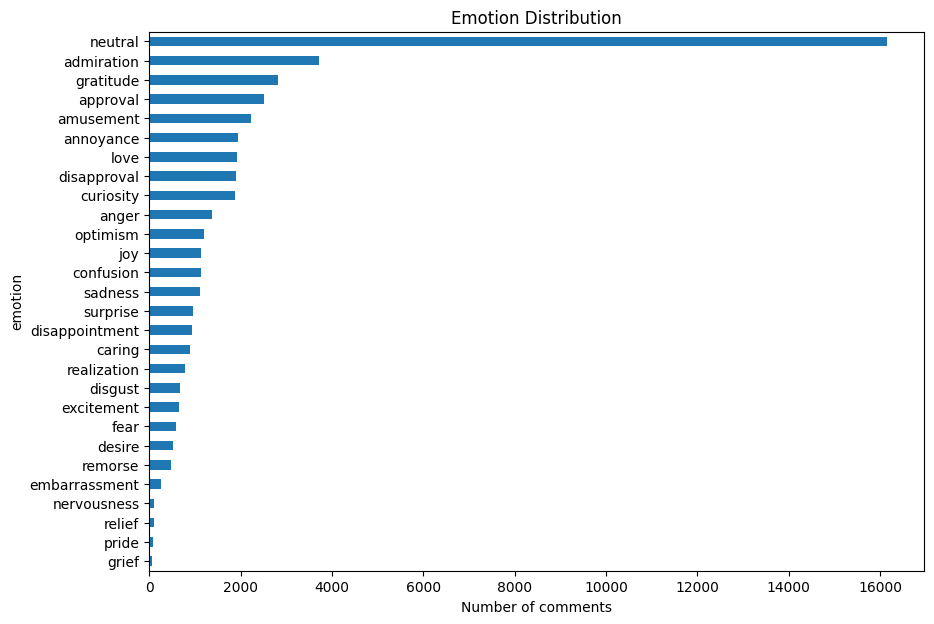

In [26]:
plt.figure(figsize=(10, 7))
data["emotion"].value_counts().sort_values().plot(kind="barh")
plt.title("Emotion Distribution")
plt.xlabel("Number of comments")
plt.show()

In [27]:
rand_train, rand_test = train_test_split(data, test_size=0.15, random_state=42)
shared = rand_test["link_id"].isin(set(rand_train["link_id"])).mean() * 100
print("Random split mein test ke itne %% comments ka thread train mein bhi hai: %.1f%%" % shared)

Random split mein test ke itne % comments ka thread train mein bhi hai: 30.2%


In [28]:
splitter1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
train_idx, temp_idx = next(splitter1.split(data, groups=data["link_id"]))
train_df = data.iloc[train_idx]
temp_df = data.iloc[temp_idx]

In [29]:
splitter2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
val_idx, test_idx = next(splitter2.split(temp_df, groups=temp_df["link_id"]))
val_df = temp_df.iloc[val_idx]
test_df = temp_df.iloc[test_idx]

In [30]:
print("Train rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Test rows:", len(test_df))

Train rows: 33677
Validation rows: 7215
Test rows: 7255


In [31]:
print("Train-Test common threads:", len(set(train_df["link_id"]) & set(test_df["link_id"])))
print("Train-Val common threads:", len(set(train_df["link_id"]) & set(val_df["link_id"])))
print("Val-Test common threads:", len(set(val_df["link_id"]) & set(test_df["link_id"])))

Train-Test common threads: 0
Train-Val common threads: 0
Val-Test common threads: 0


simple(TF-IDF)

In [32]:
always_neutral = ["neutral"] * len(val_df)
print("Sab neutral bolne par emotion accuracy: %.1f%%" % (accuracy_score(val_df["emotion"], always_neutral) * 100))
print("Sab neutral bolne par emotion F1 macro: %.1f%%" % (f1_score(val_df["emotion"], always_neutral, average="macro", zero_division=0) * 100))

Sab neutral bolne par emotion accuracy: 33.9%
Sab neutral bolne par emotion F1 macro: 1.8%


In [33]:
vectorizer = make_union(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
    TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3,
                    sublinear_tf=True, max_features=150000)
)
X_train = vectorizer.fit_transform(train_df["text"])
X_val = vectorizer.transform(val_df["text"])
X_test = vectorizer.transform(test_df["text"])
print("Features:", X_train.shape)

Features: (33677, 105220)


In [34]:
tfidf_models = {
    "Naive Bayes": ComplementNB(alpha=0.3),
    "Linear SVM (balanced)": LinearSVC(C=0.1, class_weight="balanced"),
    "Logistic Regression (balanced)": SGDClassifier(
        loss="log_loss", alpha=5e-5, class_weight="balanced", random_state=42)
}
tasks = {"Sentiment": "sentiment", "Emotion": "emotion"}

In [35]:
tfidf_rows = []
tfidf_fitted = {}
for task, col in tasks.items():
    for name, base in tfidf_models.items():
        model = clone(base)
        model.fit(X_train, train_df[col])
        pred = model.predict(X_val)
        tfidf_fitted[(task, name)] = model
        tfidf_rows.append({
            "Task": task, "Model": name,
            "Accuracy (%)": round(accuracy_score(val_df[col], pred) * 100, 2),
            "F1 Macro (%)": round(f1_score(val_df[col], pred, average="macro", zero_division=0) * 100, 2)
        })
tfidf_df = pd.DataFrame(tfidf_rows)
print(tfidf_df.sort_values(["Task", "F1 Macro (%)"], ascending=[True, False]).to_string(index=False))

     Task                          Model  Accuracy (%)  F1 Macro (%)
  Emotion Logistic Regression (balanced)         51.71         45.64
  Emotion          Linear SVM (balanced)         49.11         43.44
  Emotion                    Naive Bayes         53.44         40.82
Sentiment Logistic Regression (balanced)         67.29         64.08
Sentiment          Linear SVM (balanced)         67.33         64.05
Sentiment                    Naive Bayes         63.09         58.97


In [36]:
best_tfidf = {}
for task in tasks:
    part = tfidf_df[tfidf_df["Task"] == task].sort_values("F1 Macro (%)", ascending=False)
    best_tfidf[task] = part.iloc[0]["Model"]
    print(task, "-> CHOOSED MODEL:", best_tfidf[task])

Sentiment -> CHOOSED MODEL: Logistic Regression (balanced)
Emotion -> CHOOSED MODEL: Logistic Regression (balanced)


In [37]:
MODEL_LIST = ["distilroberta-base", "roberta-base"]
MAX_LEN = 64
EPOCHS = 5
BATCH_SIZE = 32
LEARNING_RATE = 3e-5